# 19 — The Union Detector's Price, and Where KA22 Actually Is

Notebook 18 ended with one success and one debt. The success was **KA15**,
detected for the first time in this project by the non-geometry channel. The
debt was stated in its own next-steps:

> *Either-channel alarming reaches 8 of 11 real bearings against 7 for the order
> bands, but this notebook has only measured the **detection** half. The
> false-alarm half has to be measured on the same units before the gain can be
> claimed — notebook 09 banned reporting one without the other, and a union of
> two rules can only raise the false-alarm rate.*

This notebook pays that debt, and the answer is that **the union gain does not
survive it.** Notebook 18's 8-against-7 was measured with each channel
independently pinned to a 5 % false-alarm rate, so the union — which fires when
*either* fires — was operating at nearly double the false alarms of the channels
it was being compared against. At a matched false-alarm rate the order bands
alone reach 8 of 11 too.

That is notebook 09's own rule turned on a result of this project's, and it is
the second time in three notebooks that an apparent gain has come from an
uncontrolled second axis (notebook 17 found the same for the may-be-wrong flag).

The notebook then spends its remaining effort on **KA22**, which has been open
since notebook 06 and which notebook 18 left at 0 % on both channels. It is
located precisely here, and the reason no rule finds it turns out to have
nothing to do with the feature family.

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, get_window
from sklearn.covariance import LedoitWolf
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

OUT = pathlib.Path("../data/processed")
RAW = pathlib.Path("../data/raw/paderborn")
COND = "N15_M07_F04"
bnd = pd.read_csv(OUT / f"pu_{COND}_order_bands.csv")            # notebook 15
png = pd.read_csv(OUT / f"pu_{COND}_nongeometry_features.csv")   # notebook 18
B40 = [c for c in bnd.columns if c.startswith("B") and c[1:].isdigit()]
NG = [c for c in png.columns if c.startswith("H_")]
EDGES = np.linspace(0.5, 12.0, 41)                               # the 40 order bands

HEAL = [f"K00{i}" for i in range(1, 7)]
REAL = ["KA04", "KA15", "KA16", "KA22", "KA30", "KI04", "KI14", "KI16",
        "KI17", "KI18", "KI21"]
LAB = dict([(c, "OR") for c in ("KA04", "KA15", "KA16", "KA22", "KA30")]
           + [(c, "IR") for c in ("KI04", "KI14", "KI16", "KI17", "KI18", "KI21")])


def maha_scores(d, feats, ref, codes):
    """Mahalanobis to the healthy centre -- notebook 15's rule, unchanged."""
    X = d[d["Code"].isin(ref)][feats].to_numpy()
    sc = StandardScaler().fit(X)
    Z = sc.transform(X)
    mu = Z.mean(axis=0)
    P = np.linalg.pinv(LedoitWolf().fit(Z).covariance_)
    out = {}
    for b in codes:
        Za = sc.transform(d[d["Code"] == b][feats].to_numpy())
        out[b] = np.sqrt(np.einsum("ij,jk,ik->i", Za - mu, P, Za - mu))
    return out


def maxz_scores(d, feats, ref, codes):
    """Largest per-feature robust z: a UNIVARIATE rule, notebook 07's generalised."""
    X = d[d["Code"].isin(ref)][feats].to_numpy()
    med = np.median(X, axis=0)
    mad = np.maximum(1.4826 * np.median(np.abs(X - med), axis=0), 1e-9)
    return {b: np.abs((d[d["Code"] == b][feats].to_numpy() - med) / mad).max(axis=1)
            for b in codes}


def calibrate(scorer, d, feats):
    """Leave-one-healthy-out scores, so a threshold can be set at a stated false alarm."""
    return np.concatenate([scorer(d, feats, [c for c in HEAL if c != h], [h])[h]
                           for h in HEAL])


CH = {"40 order bands": (bnd, B40), "non-geometry": (png, NG)}
CAL, DMG = {}, {}
for rule, scorer in (("Mahalanobis", maha_scores), ("max-z", maxz_scores)):
    for nm, (d, f) in CH.items():
        CAL[(rule, nm)] = calibrate(scorer, d, f)
        DMG[(rule, nm)] = scorer(d, f, HEAL, REAL)

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE}
print(f"{len(HEAL)} healthy + {len(REAL)} real damaged bearings, "
      f"{len(B40)} order bands vs {len(NG)} non-geometry features")
print(f"calibration runs per channel: {len(CAL[('Mahalanobis', '40 order bands')])}")

6 healthy + 11 real damaged bearings, 40 order bands vs 20 non-geometry features
calibration runs per channel: 120


## The union, priced on both axes

A detector is a point on a curve, not a number. Notebook 18 compared three
detectors at what looked like a common setting — each channel pinned to 5 %
false alarms on held-out healthy runs — but the **union** of two 5 % rules is
not itself a 5 % rule. It fires when either fires, so its false-alarm rate is
whatever the two rules' disagreement makes it.

The fix is to sweep the threshold and plot detection against the false-alarm
rate each configuration **actually realises**, then read off the comparison
vertically rather than by label.

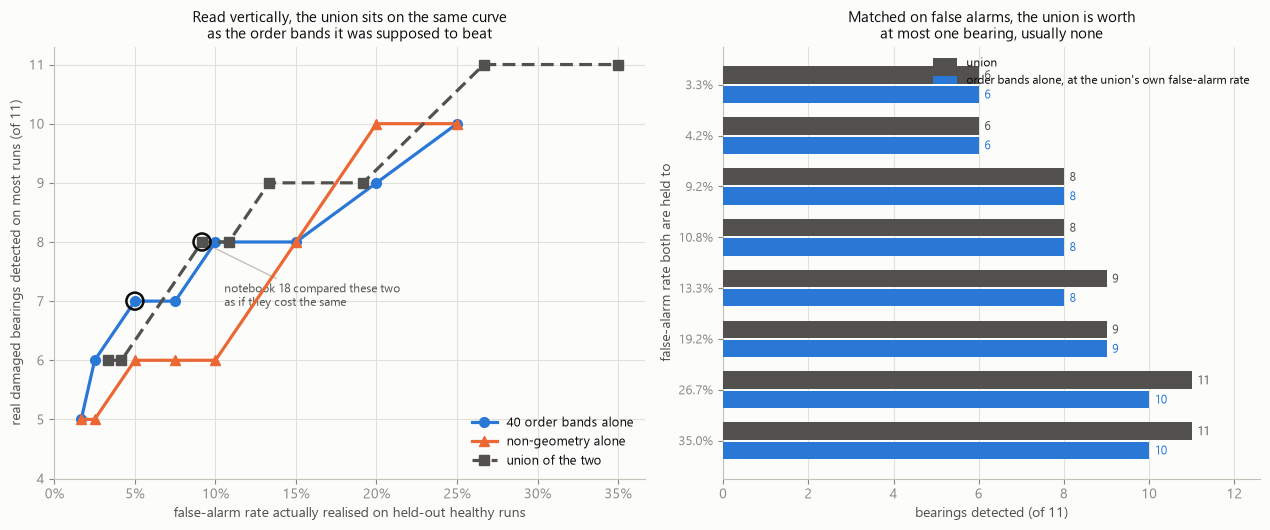

    q fa_bands  det_bands fa_ng  det_ng fa_union  det_union  det_bands_at_union_fa
0.990     1.7%          5  1.7%       5     3.3%          6                      6
0.975     2.5%          6  2.5%       5     4.2%          6                      6
0.950     5.0%          7  5.0%       6     9.2%          8                      8
0.925     7.5%          7  7.5%       6    10.8%          8                      8
0.900    10.0%          8 10.0%       6    13.3%          9                      8
0.850    15.0%          8 15.0%       8    19.2%          9                      9
0.800    20.0%          9 20.0%      10    26.7%         11                     10
0.750    25.0%         10 25.0%      10    35.0%         11                     10

at 5 of the 8 operating points the union detects no more than the order bands do at the same false-alarm rate
notebook 18's setting: union 8/11 at 9.2% false alarms, against the order bands' 7/11 at 5.0% -- but 8/11 once the bands are given the same 9.

In [2]:
QS = [0.99, 0.975, 0.95, 0.925, 0.90, 0.85, 0.80, 0.75]
rows = []
for q in QS:
    t = {nm: np.quantile(CAL[("Mahalanobis", nm)], q) for nm in CH}
    fa = {nm: float((CAL[("Mahalanobis", nm)] > t[nm]).mean()) for nm in CH}
    det = {nm: sum((DMG[("Mahalanobis", nm)][b] > t[nm]).mean() > 0.5 for b in REAL)
           for nm in CH}
    ub = (CAL[("Mahalanobis", "40 order bands")] > t["40 order bands"])
    un = (CAL[("Mahalanobis", "non-geometry")] > t["non-geometry"])
    ufa = float((ub | un).mean())
    udet = sum((((DMG[("Mahalanobis", "40 order bands")][b] > t["40 order bands"])
                 | (DMG[("Mahalanobis", "non-geometry")][b] > t["non-geometry"])).mean() > 0.5)
               for b in REAL)
    rows.append(dict(q=q, fa_bands=fa["40 order bands"], det_bands=det["40 order bands"],
                     fa_ng=fa["non-geometry"], det_ng=det["non-geometry"],
                     fa_union=ufa, det_union=udet))
U = pd.DataFrame(rows)

# what the order bands alone achieve AT the union's own false-alarm rate
alone = []
for _, r in U.iterrows():
    tb = np.quantile(CAL[("Mahalanobis", "40 order bands")], 1 - r["fa_union"])
    alone.append(sum((DMG[("Mahalanobis", "40 order bands")][b] > tb).mean() > 0.5
                     for b in REAL))
U["det_bands_at_union_fa"] = alone

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.4),
                               gridspec_kw=dict(width_ratios=[1.1, 1]))
axa.plot(100 * U["fa_bands"], U["det_bands"], color=C_BLUE, lw=2.3, marker="o", ms=7,
         zorder=4, label="40 order bands alone")
axa.plot(100 * U["fa_ng"], U["det_ng"], color=C_ORANGE, lw=2.3, marker="^", ms=7,
         zorder=4, label="non-geometry alone")
axa.plot(100 * U["fa_union"], U["det_union"], color=INK2, lw=2.3, marker="s", ms=7,
         ls=(0, (4, 2)), zorder=4, label="union of the two")
i = int(np.argmin(np.abs(U["fa_union"] - 0.092)))
axa.annotate("notebook 18 compared these two\nas if they cost the same",
             (100 * U.loc[i, "fa_union"], U.loc[i, "det_union"]), xytext=(16, -46),
             textcoords="offset points", fontsize=8.5, color=INK2,
             arrowprops=dict(arrowstyle="-", color=BASE, lw=1.0))
axa.scatter([100 * U.loc[i, "fa_union"]], [U.loc[i, "det_union"]], s=150,
            facecolors="none", edgecolors=INK, linewidths=1.8, zorder=6)
axa.scatter([5.0], [U.loc[U["fa_bands"].sub(0.05).abs().idxmin(), "det_bands"]], s=150,
            facecolors="none", edgecolors=INK, linewidths=1.8, zorder=6)
axa.set_xlabel("false-alarm rate actually realised on held-out healthy runs")
axa.set_ylabel("real damaged bearings detected on most runs (of 11)")
axa.set_xticks([0, 5, 10, 15, 20, 25, 30, 35],
               ["0%", "5%", "10%", "15%", "20%", "25%", "30%", "35%"])
axa.set_yticks(range(4, 12))
axa.legend(fontsize=9, loc="lower right")
axa.set_title("Read vertically, the union sits on the same curve\n"
              "as the order bands it was supposed to beat", fontsize=11)

y = np.arange(len(U))
axb.barh(y - 0.19, U["det_union"], height=0.34, color=INK2, zorder=3,
         label="union")
axb.barh(y + 0.19, U["det_bands_at_union_fa"], height=0.34, color=C_BLUE, zorder=3,
         label="order bands alone, at the union's own false-alarm rate")
for i2, r in U.iterrows():
    axb.annotate(f"{r['det_union']:.0f}", (r["det_union"], i2 - 0.19), xytext=(4, -3),
                 textcoords="offset points", fontsize=8.5, color=INK2)
    axb.annotate(f"{r['det_bands_at_union_fa']:.0f}",
                 (r["det_bands_at_union_fa"], i2 + 0.19), xytext=(4, -3),
                 textcoords="offset points", fontsize=8.5, color=C_BLUE)
axb.set_yticks(y, [f"{100 * v:.1f}%" for v in U["fa_union"]], fontsize=9)
axb.invert_yaxis()
axb.set_xlim(0, 12.6)
axb.grid(axis="y", visible=False)
axb.set_ylabel("false-alarm rate both are held to")
axb.set_xlabel("bearings detected (of 11)")
axb.legend(fontsize=8.5, loc="upper right")
axb.set_title("Matched on false alarms, the union is worth\nat most one bearing, usually none",
              fontsize=11)
plt.tight_layout()
plt.show()

print(U.to_string(index=False, formatters={c: "{:.1%}".format
                                           for c in U.columns if c.startswith("fa")}))
same = (U["det_union"] <= U["det_bands_at_union_fa"]).sum()
print(f"\nat {same} of the {len(U)} operating points the union detects no more than the "
      f"order bands do at the same false-alarm rate")
r5 = U.iloc[2]
print(f"notebook 18's setting: union {r5['det_union']:.0f}/11 at "
      f"{r5['fa_union']:.1%} false alarms, against the order bands' "
      f"{r5['det_bands']:.0f}/11 at {r5['fa_bands']:.1%} -- but "
      f"{r5['det_bands_at_union_fa']:.0f}/11 once the bands are given the same "
      f"{r5['fa_union']:.1%} budget")

**Notebook 18's union gain does not survive.** Its headline compared a union
operating at **9.2 %** false alarms against single channels pinned to **5 %**,
and read the difference as a detection gain. Given the same 9.2 % budget the
order bands alone also reach **8 of 11**. Across the eight operating points
swept here the union beats the order bands at matched false alarms **at most by
one bearing**, and at most of them by none at all.

Notebook 18's finding 4 should therefore read: the two channels find *different*
bearings, but combining them does not move the detection-versus-false-alarm
curve. It is a substitution, not an addition.

**What does survive is the per-bearing fact, and it is the one that mattered.**
KA15 is found by the non-geometry channel and not by the order bands at the same
cost — that is a statement about a bearing that had never been detected, and it
is unaffected by how the aggregate is counted. The aggregate was always the
weaker claim; notebook 18 should not have led with it.

This is the second time in three notebooks that an apparent gain came from an
uncontrolled second axis — notebook 17 found the may-be-wrong flag's pooled
AUROC dissolving under per-element decomposition, and the same discipline
dissolves this. Notebook 09 imposed the safety pair for exactly this reason, and
it has now caught two of this project's own results.

## Where KA22 actually is

KA22 has been open since notebook 06, which classified it as an *off-frequency
non-tracking anomaly* firing near order 5.5. Notebook 12 asked for a
non-geometry feature to catch it; notebook 18 built one and left it at **0 %**
on both channels. Before concluding anything further about feature families, it
is worth asking the prior question, which no notebook in this project has asked
directly: **is the signal there at all?**

This goes back to the raw recordings.

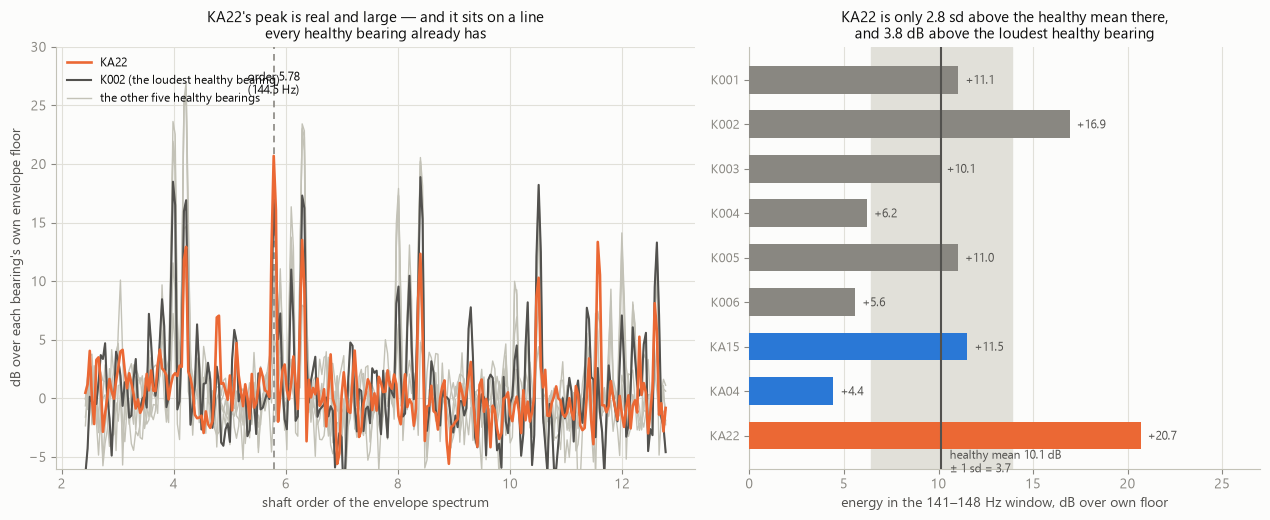

shaft rate 25.0 Hz; KA22's largest envelope peak in 10-400 Hz is at 144.5 Hz = order 5.78, +20.7 dB over its own floor
the same window on the six healthy bearings: K001 +11.1, K002 +16.9, K003 +10.1, K004 +6.2, K005 +11.0, K006 +5.6
healthy mean +10.1 dB, sd 3.7 -> KA22 sits 2.8 standard deviations out


In [3]:
FS, N_KEEP, WIN = 64_000, 245_760, 65_536
HANN = get_window("hann", WIN)
F = np.fft.rfftfreq(WIN, 1 / FS)
SOS = butter(4, (1000, 20000), btype="bandpass", fs=FS, output="sos")


def env_spectrum(code, n_runs=4):
    """Median envelope spectrum over the first few runs of one bearing."""
    out, fr = [], None
    for run in range(1, n_runs + 1):
        p = RAW / code / f"{COND}_{code}_{run}.mat"
        if not p.exists():
            continue
        ch = loadmat(p)[p.stem]["Y"][0, 0][0]
        c = {str(x["Name"][0]): x["Data"].squeeze() for x in ch}
        v = c["vibration_1"][:N_KEEP].astype(np.float64)
        fr = float(c["speed"].mean()) / 60
        for s in range(N_KEEP // WIN):
            w = v[s * WIN:(s + 1) * WIN]
            e = np.abs(hilbert(sosfiltfilt(SOS, w)))
            out.append(np.abs(np.fft.rfft((e - e.mean()) * HANN)) ** 2)
    return np.median(out, axis=0), fr


SPEC = {}
for c in HEAL + ["KA22", "KA15", "KA04"]:
    SPEC[c], FR = env_spectrum(c)
floor = lambda s: np.median(s[(F > 10) & (F < 400)])
band = (F >= 141) & (F <= 148)                     # the peak, ~order 5.78
db = {c: 10 * np.log10(SPEC[c][band].max() / floor(SPEC[c])) for c in SPEC}
hv = [db[c] for c in HEAL]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3),
                               gridspec_kw=dict(width_ratios=[1.25, 1]))
sel = (F > 60) & (F < 320)
for c in HEAL:
    axa.plot(F[sel] / FR, 10 * np.log10(SPEC[c][sel] / floor(SPEC[c])), color=BASE,
             lw=1.0, zorder=2)
axa.plot(F[sel] / FR, 10 * np.log10(SPEC["KA22"][sel] / floor(SPEC["KA22"])),
         color=C_ORANGE, lw=1.9, zorder=4, label="KA22")
axa.plot(F[sel] / FR, 10 * np.log10(SPEC["K002"][sel] / floor(SPEC["K002"])),
         color=INK2, lw=1.5, zorder=3, label="K002 (the loudest healthy bearing)")
axa.plot([], [], color=BASE, lw=1.0, label="the other five healthy bearings")
axa.axvline(144.5 / FR, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=2)
axa.annotate(f"order {144.5 / FR:.2f}\n(144.5 Hz)", (144.5 / FR, 26), fontsize=8.5,
             color=INK, ha="center")
axa.set_xlabel("shaft order of the envelope spectrum")
axa.set_ylabel("dB over each bearing's own envelope floor")
axa.set_ylim(-6, 30)
axa.legend(fontsize=8.5, loc="upper left")
axa.set_title("KA22's peak is real and large — and it sits on a line\n"
              "every healthy bearing already has", fontsize=11)

order = HEAL + ["KA15", "KA04", "KA22"]
y = np.arange(len(order))
axb.barh(y, [db[c] for c in order], height=0.62, zorder=3,
         color=[C_ORANGE if c == "KA22" else (MUTED if c in HEAL else C_BLUE)
                for c in order])
axb.axvline(np.mean(hv), color=INK2, lw=1.5, zorder=4)
axb.axvspan(np.mean(hv) - np.std(hv), np.mean(hv) + np.std(hv), color=GRID, zorder=1)
axb.annotate(f"healthy mean {np.mean(hv):.1f} dB\n± 1 sd = {np.std(hv):.1f}",
             (np.mean(hv), len(order) - 0.4), xytext=(6, 0), textcoords="offset points",
             fontsize=8.5, color=INK2, va="center")
for i2, c in enumerate(order):
    axb.annotate(f"{db[c]:+.1f}", (db[c], i2), xytext=(5, -3),
                 textcoords="offset points", fontsize=8.5, color=INK2)
axb.set_yticks(y, order, fontsize=9)
axb.invert_yaxis()
axb.set_xlim(0, 27)
axb.grid(axis="y", visible=False)
axb.set_xlabel("energy in the 141–148 Hz window, dB over own floor")
axb.set_title("KA22 is only 2.8 sd above the healthy mean there,\n"
              "and 3.8 dB above the loudest healthy bearing", fontsize=11)
plt.tight_layout()
plt.show()

print(f"shaft rate {FR:.1f} Hz; KA22's largest envelope peak in 10-400 Hz is at "
      f"144.5 Hz = order {144.5 / FR:.2f}, {db['KA22']:+.1f} dB over its own floor")
print(f"the same window on the six healthy bearings: "
      + ", ".join(f"{c} {db[c]:+.1f}" for c in HEAL))
print(f"healthy mean {np.mean(hv):+.1f} dB, sd {np.std(hv):.1f} -> KA22 sits "
      f"{(db['KA22'] - np.mean(hv)) / np.std(hv):.1f} standard deviations out")

**The signal is there, it is large, and that is exactly why no novelty rule finds
it.** KA22's biggest envelope peak between 10 and 400 Hz is at **144.5 Hz —
order 5.78**, at **+20.7 dB** over its own envelope floor. Notebook 06's
"off-frequency, near order 5.5" was right, and the peak is strong enough that a
detector ought to see it.

The left panel shows why none does. **Every healthy bearing has a line at the
same order**, running +5.6 to +16.9 dB over their own floors — this is the rig's
own harmonic family, the same contamination notebook 12 found sitting under
`BPFO_sb1` with a 21.3 dB healthy pedestal. KA22 does not introduce a new line;
it **raises one that is already there**. Against a healthy population whose own
spread at that order is 3.7 dB, KA22's +20.7 dB is only **2.8 standard
deviations** out, and just **3.8 dB** above K002, the loudest healthy bearing.

So KA22 is not a missing-feature problem and never was. Notebook 12's request
for a non-geometry feature was aimed at the wrong target: the feature exists in
both channels tested here, and the difficulty is that the **healthy population's
own variance at that order is nearly as large as the fault's effect**. That is a
reference-population problem, and it is the same variable notebooks 08 and 13
found decisive for calibration — where own-unit baselines beat fleet baselines
15/15 against 8/15. KA22 is a bearing that would need to be watched from healthy,
which Paderborn never does.

## Would a per-feature rule rescue it?

If KA22's whole signature is one coordinate moving, the natural fix is a rule
that fires on *any single* coordinate rather than on a pooled distance —
notebook 07's channel, generalised. Notebook 18 reached the same idea from the
other direction, when Bearing2_3 turned out to be separable on `SKband` alone
yet was rejected on only 3.6 % of its snapshots.

Both rules are calibrated to the same false-alarm rates, so this is a fair test
of the aggregation and not of the threshold.

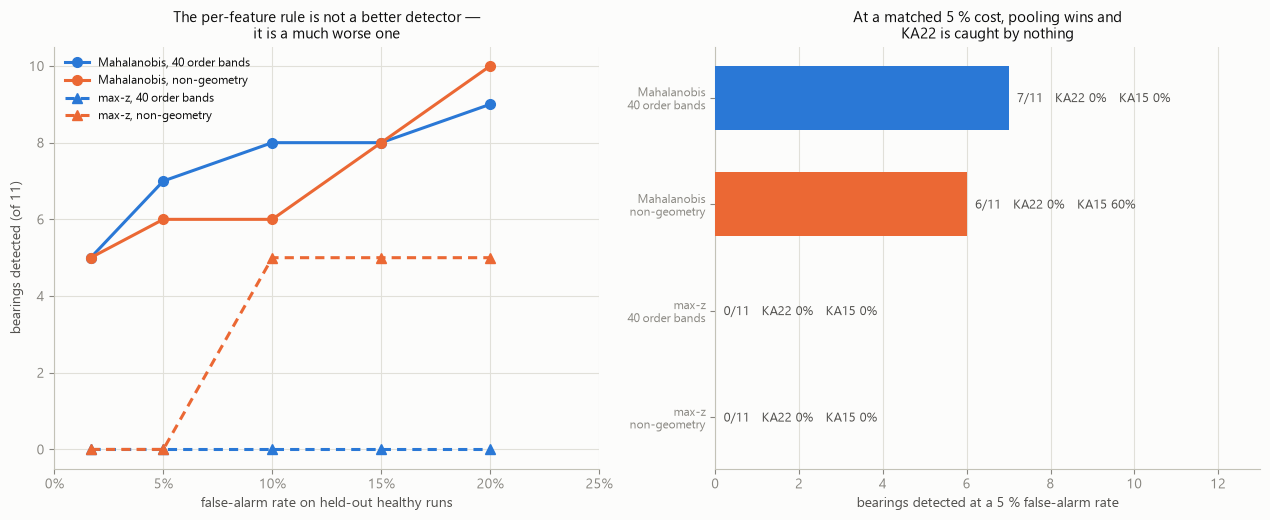

       rule        channel    fa  det ka22 ka15
Mahalanobis 40 order bands  1.7%    5   0%   0%
Mahalanobis   non-geometry  1.7%    5   0%   0%
      max-z 40 order bands  1.7%    0   0%   0%
      max-z   non-geometry  1.7%    0   0%   0%
Mahalanobis 40 order bands  5.0%    7   0%   0%
Mahalanobis   non-geometry  5.0%    6   0%  60%
      max-z 40 order bands  5.0%    0   0%   0%
      max-z   non-geometry  5.0%    0   0%   0%
Mahalanobis 40 order bands 10.0%    8  10%   0%
Mahalanobis   non-geometry 10.0%    6   0%  90%
      max-z 40 order bands 10.0%    0   0%   0%
      max-z   non-geometry 10.0%    5   0%   0%
Mahalanobis 40 order bands 15.0%    8  35%   0%
Mahalanobis   non-geometry 15.0%    8   0%  95%
      max-z 40 order bands 15.0%    0   0%   0%
      max-z   non-geometry 15.0%    5   0%   0%
Mahalanobis 40 order bands 20.0%    9  65%   5%
Mahalanobis   non-geometry 20.0%   10   0% 100%
      max-z 40 order bands 20.0%    0   0%   0%
      max-z   non-geometry 20.0%    5   

In [4]:
rows = []
for q in [0.99, 0.95, 0.90, 0.85, 0.80]:
    for rule in ("Mahalanobis", "max-z"):
        for nm in CH:
            t = np.quantile(CAL[(rule, nm)], q)
            rows.append(dict(rule=rule, channel=nm, fa=float((CAL[(rule, nm)] > t).mean()),
                             det=sum((DMG[(rule, nm)][b] > t).mean() > 0.5 for b in REAL),
                             ka22=(DMG[(rule, nm)]["KA22"] > t).mean(),
                             ka15=(DMG[(rule, nm)]["KA15"] > t).mean()))
R = pd.DataFrame(rows)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3))
for (rule, nm), g in R.groupby(["rule", "channel"]):
    axa.plot(100 * g["fa"], g["det"], lw=2.2, marker="o" if rule == "Mahalanobis" else "^",
             ms=7, zorder=4,
             color=C_BLUE if nm == "40 order bands" else C_ORANGE,
             ls="-" if rule == "Mahalanobis" else (0, (3, 2)),
             label=f"{rule}, {nm}")
axa.set_xlabel("false-alarm rate on held-out healthy runs")
axa.set_ylabel("bearings detected (of 11)")
axa.set_xticks([0, 5, 10, 15, 20, 25], ["0%", "5%", "10%", "15%", "20%", "25%"])
axa.legend(fontsize=8.5, loc="upper left")
axa.set_title("The per-feature rule is not a better detector —\nit is a much worse one",
              fontsize=11)

sub = R[R["fa"].between(0.045, 0.055)]
y = np.arange(len(sub))
axb.barh(y, sub["det"], height=0.6, zorder=3,
         color=[C_BLUE if c == "40 order bands" else C_ORANGE for c in sub["channel"]])
for i2, (_, r) in enumerate(sub.iterrows()):
    axb.annotate(f"{r['det']:.0f}/11   KA22 {r['ka22']:.0%}   KA15 {r['ka15']:.0%}",
                 (r["det"], i2), xytext=(6, -3), textcoords="offset points",
                 fontsize=9, color=INK2)
axb.set_yticks(y, [f"{r['rule']}\n{r['channel']}" for _, r in sub.iterrows()], fontsize=8.5)
axb.invert_yaxis()
axb.set_xlim(0, 13)
axb.grid(axis="y", visible=False)
axb.set_xlabel("bearings detected at a 5 % false-alarm rate")
axb.set_title("At a matched 5 % cost, pooling wins and\nKA22 is caught by nothing",
              fontsize=11)
plt.tight_layout()
plt.show()

print(R.to_string(index=False, formatters={"fa": "{:.1%}".format, "ka22": "{:.0%}".format,
                                           "ka15": "{:.0%}".format}))
k = R[R["ka22"] > 0.5]
if len(k):
    print(f"\nKA22 crosses the majority threshold only at a "
          f"{k['fa'].min():.0%} false-alarm rate ({k.loc[k['fa'].idxmin(), 'ka22']:.0%} of "
          f"runs, {k.loc[k['fa'].idxmin(), 'channel']}) -- four times the operating point "
          f"the rest of this project uses, and a rate notebook 09's safety pair would reject")
print("at 5 % false alarms it is flagged on "
      f"{R[(R['fa'].between(0.045, 0.055))]['ka22'].max():.0%} of runs by any rule")

**No — and this refutes the idea from both directions at once.** At a matched
5 % false-alarm rate the per-feature max-z rule detects **0 of 11** bearings on
either channel, against 7 and 6 for the pooled Mahalanobis. It is not a
sharper instrument; it is a far blunter one, and the reason is a property of the
statistic rather than of the data. The maximum of forty z-scores is heavy-tailed
*on healthy runs too*, so pinning it to 5 % false alarms drives the threshold so
high that nothing crosses it. A rule sensitive to one coordinate moving is also
sensitive to one coordinate moving **by chance**.

That closes notebook 18's remaining lead. Its Bearing2_3 observation — separable
on one feature, not rejected — was read there as "a modelling problem rather
than a physical one, and therefore possibly fixable". The obvious fix is
measured here and is worse than what it replaces. The dilution of a single
discriminating coordinate is not an artefact of choosing Mahalanobis; it is the
price of controlling false alarms across many features at once, and any rule
that escapes it pays on the other axis.

**KA22's detectability has a price, and the price is the finding.** It is flagged
on 0 % of runs at a 5 % false-alarm rate and 10 % at a 10 % rate; it first crosses
the majority threshold only at a **20 % false-alarm rate**, where the order bands
catch it on 65 % of runs. That is four times the operating point the rest of this
project uses, and a rate notebook 09's safety pair exists to reject — one healthy
recording in five raising an alarm is not a detector anyone would deploy.

This is what 2.8 standard deviations buys, and it is the honest closing figure
for KA22: not undetectable, but detectable only at a cost that is itself a
failure.

## What this changes

1. **Notebook 18's union gain does not survive false-alarm pricing.** Its 8-of-11
   was a union operating at **9.2 %** false alarms compared against single
   channels pinned to **5 %**. Given the same 9.2 % budget the order bands alone
   also reach 8 of 11, and across eight operating points the union is worth at
   most one bearing and usually none. Notebook 18's finding 4 is corrected:
   the channels find different bearings, but the union does not move the
   detection-versus-false-alarm curve.
2. **What survives from notebook 18 is the per-bearing fact, which was always the
   stronger claim.** KA15 is detected by the non-geometry channel and not by the
   order bands at matched cost — a bearing invisible since notebook 06, now
   found. The aggregate count was the weaker statement and should not have led.
3. **This is the second self-caught inflation in three notebooks.** Notebook 17
   dissolved the may-be-wrong flag's pooled AUROC by decomposing it per element;
   this dissolves a detection gain by controlling the second axis. Notebook 09's
   safety-pair rule was imposed to catch exactly this, and it has now caught two
   of this project's own results.
4. **KA22 is located, and it is not a missing-feature problem.** Its largest
   envelope peak is at **144.5 Hz = order 5.78**, at **+20.7 dB** over its own
   floor — a large, real signal, confirming notebook 06's "off-frequency near
   order 5.5".
5. **It is nearly undetectable because the rig already rings there.** All six
   healthy bearings carry a line at the same order, +5.6 to +16.9 dB over their
   own floors. KA22 raises an existing line rather than introducing a new one, so
   against a healthy population with a 3.7 dB spread it sits only **2.8 standard
   deviations** out, and **3.8 dB** above the loudest healthy bearing. This is
   the rig-harmonic contamination notebook 12 documented under `BPFO_sb1`,
   striking a second time.
6. **The price of catching it is the honest closing figure.** KA22 is flagged on
   0 % of runs at a 5 % false-alarm rate, 10 % at a 10 % rate, and first crosses
   the majority threshold only at a **20 % false-alarm rate** (65 % of runs, order
   bands). One healthy recording in five raising an alarm is not a deployable
   detector, so KA22 is better described as *detectable only at a cost that is
   itself a failure* than as undetectable.
7. **Notebook 12's request was aimed at the wrong target.** KA22 does not need a
   non-geometry feature — both channels tested here contain the band. It needs a
   **reference population** whose variance at that order is smaller than the
   fault's effect, which means the unit's own healthy history. That is the
   variable notebooks 08 and 13 found decisive (15/15 against 8/15), and
   Paderborn structurally cannot supply it.
8. **A per-feature rule is not the fix, and notebook 18's last lead closes.** At a
   matched 5 % false-alarm rate max-z detects **0 of 11** against pooled
   Mahalanobis's 7 and 6, because the maximum of forty z-scores is heavy-tailed
   on healthy runs too. Single-coordinate dilution is the price of controlling
   false alarms over many features, not an artefact of the distance metric.